In [1]:
# RQ7: how the decision threshold trades attack recall against false positives, using the saved scores of each
# Task A model (no training). Thresholds are chosen on validation only, then applied once to both test sets.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/task_a").is_dir())

In [2]:
# Latest saved predictions of each model; "score" is P(adversarial) for LogReg/DistilBERT and the SVM decision score.
model_folders = {"LogReg": "results/task_a_binary_tfidf_v2", "SVM": "results/task_a_binary_tfidf_linear_svm_v2",
                 "DistilBERT": "results/task_a_binary_distilbert_v2", "DistilBERT-512": "results/task_a_binary_distilbert_512_v2"}
default_threshold = {"LogReg": 0.5, "SVM": 0.0, "DistilBERT": 0.5, "DistilBERT-512": 0.5}
scores = {}
for model, folder in model_folders.items():
    prediction_file = sorted((ROOT / folder).glob("run_*/predictions.csv"))[-1]
    scores[model] = pd.read_csv(prediction_file)
    print(f"{model}: {prediction_file.parent.name}")

LogReg: run_20261021T022858Z
SVM: run_20261021T022904Z
DistilBERT: run_20261021T024649Z
DistilBERT-512: run_20261021T231957Z


In [3]:
# Operating points: the model's default threshold, and the threshold with the highest validation recall whose
# validation false-positive rate stays at or below 1% and 5%. Test labels play no part in choosing them.
def threshold_for_fpr(validation, max_fpr):
    fpr, recall, thresholds = roc_curve(validation["gold"], validation["score"])
    allowed = fpr <= max_fpr
    return float(thresholds[allowed][np.argmax(recall[allowed])])

operating_points = {}
for model, frame in scores.items():
    validation = frame[frame["split"] == "validation"]
    operating_points[model] = {"default": default_threshold[model], "val FPR <= 1%": threshold_for_fpr(validation, 0.01),
                               "val FPR <= 5%": threshold_for_fpr(validation, 0.05)}
pd.DataFrame(operating_points).T.round(4)

,default,val FPR <= 1%,val FPR <= 5%
LogReg,0.5,0.6257,0.2235
SVM,0.0,0.0675,-0.3852
DistilBERT,0.5,0.3509,0.0221
DistilBERT-512,0.5,0.6817,0.0471


In [4]:
# Attack recall and false-positive rate at each operating point, on validation and both test sets.
split_names = {"validation": "Validation", "test_official": "Official WildGuardMix test", "test_jailbreakhub": "JailbreakHub test"}
rows = {}
for model, frame in scores.items():
    for point, threshold in operating_points[model].items():
        row = {}
        for split, name in split_names.items():
            part = frame[frame["split"] == split]
            flagged = part["score"] >= threshold
            row[(name, "recall")] = flagged[part["gold"] == 1].mean()
            row[(name, "FPR")] = flagged[part["gold"] == 0].mean()
        rows[(model, point)] = row
trade_off = pd.DataFrame(rows).T
trade_off.style.format("{:.3f}")

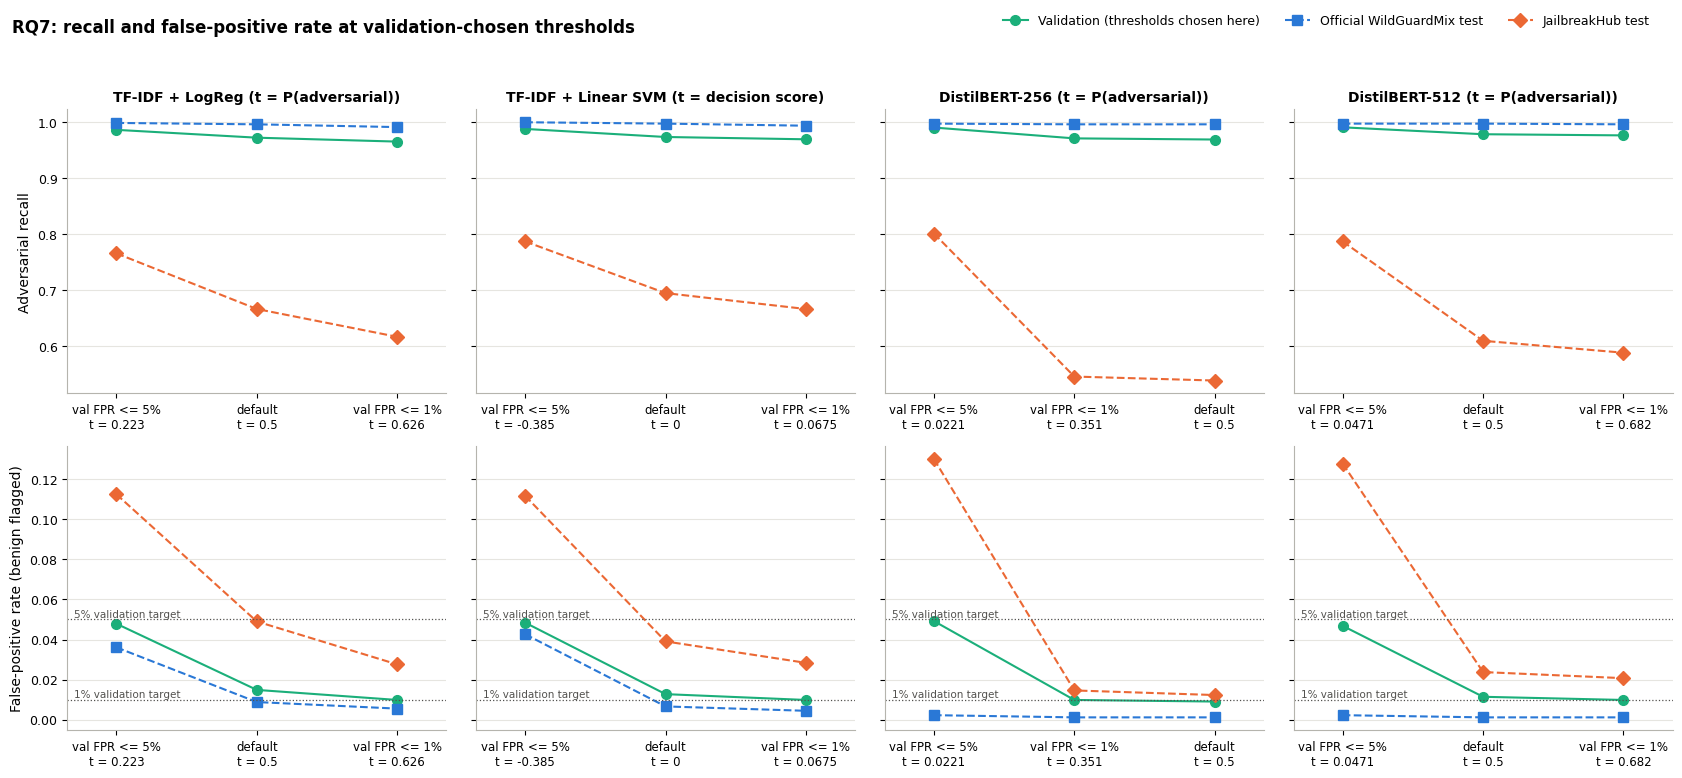

In [5]:
# Recall and FPR at the three evaluated operating points only (validation-chosen thresholds, table above), ordered by
# threshold and evenly spaced; lines only connect measured points. The figure style is restored at the end of the cell.
sys.path.insert(0, str(ROOT / "src"))
from task_a.plotting import MODEL_LABELS, SPLIT_COLORS, TEXT_SECONDARY, apply_style

split_styles = {"validation": ("-", "o"), "test_official": ("--", "s"), "test_jailbreakhub": ("--", "D")}
split_labels = {"validation": "Validation (thresholds chosen here)", "test_official": "Official WildGuardMix test",
                "test_jailbreakhub": "JailbreakHub test"}
previous_style = apply_style()
fig, axes = plt.subplots(2, len(scores), figsize=(17, 7.8), sharey="row")
for col, model in enumerate(scores):
    points = sorted(operating_points[model].items(), key=lambda item: item[1])
    x = np.arange(len(points))
    for row, metric in enumerate(["recall", "FPR"]):
        ax = axes[row, col]
        for split, name in split_names.items():
            linestyle, marker = split_styles[split]
            ax.plot(x, [trade_off.loc[(model, point), (name, metric)] for point, _ in points], linestyle=linestyle,
                    marker=marker, markersize=7, linewidth=1.5, color=SPLIT_COLORS[split], label=split_labels[split])
        ax.set_xticks(x, [f"{point}\nt = {threshold:.3g}" for point, threshold in points], fontsize=8.5)
        ax.set_xlim(-0.35, len(points) - 0.65)
    for target in (0.01, 0.05):
        axes[1, col].axhline(target, color=TEXT_SECONDARY, linewidth=0.9, linestyle=":")
        axes[1, col].text(-0.3, target, f"{target:.0%} validation target", fontsize=7.5, color=TEXT_SECONDARY, va="bottom")
    axes[0, col].set_title(MODEL_LABELS[model] + (" (t = decision score)" if model == "SVM" else " (t = P(adversarial))"),
                           fontsize=10)
axes[0, 0].set_ylabel("Adversarial recall")
axes[1, 0].set_ylabel("False-positive rate (benign flagged)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(0.98, 1.0), ncol=3)
fig.suptitle("RQ7: recall and false-positive rate at validation-chosen thresholds", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
plt.rcParams.update(previous_style)  # the existing curve figure below keeps its original look

**Figure: recall and FPR at the three evaluated thresholds per model.** Validation (green, solid) is the split where each threshold was chosen. The two test lines (dashed) show the result of applying that threshold once. Only three thresholds per model were evaluated, and the connecting lines do not imply measurements between them. No threshold was selected or tuned on a test set. The recall-vs-FPR curves in the next cell sweep test thresholds for description only.

- **Official WildGuardMix test:** stays close to validation.
- **JailbreakHub test:** the "val FPR <= 5%" thresholds raise recall to 0.77–0.80, but give an FPR of 0.11–0.13, more than twice the 5% target.

A validation FPR target therefore did not carry over to this test set. Validation is about 77% WildGuardMix (4,772 of 6,212 prompts), so the chosen thresholds mostly reflect WildGuardMix prompts. For DistilBERT-256 the default threshold of 0.5 is stricter than the "val FPR <= 1%" threshold, so the two operating points swap order on its x-axis.

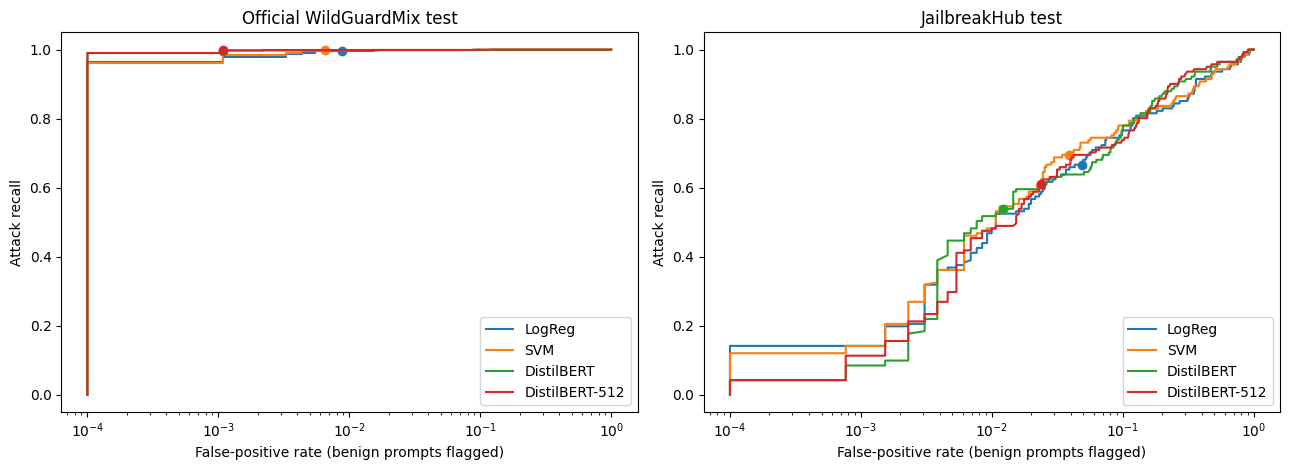

In [6]:
# Recall-vs-FPR curves on each test set (log scale for FPR); dots mark the default threshold.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, split in zip(axes, ["test_official", "test_jailbreakhub"]):
    for model, frame in scores.items():
        part = frame[frame["split"] == split]
        fpr, recall, _ = roc_curve(part["gold"], part["score"])
        line, = ax.plot(np.clip(fpr, 1e-4, 1), recall, label=model)
        flagged = part["score"] >= default_threshold[model]
        ax.plot(max(flagged[part["gold"] == 0].mean(), 1e-4), flagged[part["gold"] == 1].mean(), "o", color=line.get_color())
    ax.set_xscale("log")
    ax.set_title(split_names[split])
    ax.set_xlabel("False-positive rate (benign prompts flagged)")
    ax.set_ylabel("Attack recall")
    ax.legend(loc="lower right")
fig.tight_layout()

In [7]:
# Summary generated from the table above: what a stricter or looser validation-chosen threshold changes on JailbreakHub.
for model in scores:
    default, loose = trade_off.loc[(model, "default")], trade_off.loc[(model, "val FPR <= 5%")]
    print(f"{model}: JailbreakHub recall {default[('JailbreakHub test', 'recall')]:.3f} -> {loose[('JailbreakHub test', 'recall')]:.3f} "
          f"and FPR {default[('JailbreakHub test', 'FPR')]:.3f} -> {loose[('JailbreakHub test', 'FPR')]:.3f} "
          "when moving from the default threshold to the validation FPR <= 5% threshold.")
print("Thresholds were chosen on validation; validation is mostly WildGuardMix, so they may not transfer to JailbreakHub.")

LogReg: JailbreakHub recall 0.667 -> 0.766 and FPR 0.049 -> 0.113 when moving from the default threshold to the validation FPR <= 5% threshold.
SVM: JailbreakHub recall 0.695 -> 0.787 and FPR 0.039 -> 0.112 when moving from the default threshold to the validation FPR <= 5% threshold.
DistilBERT: JailbreakHub recall 0.539 -> 0.801 and FPR 0.012 -> 0.130 when moving from the default threshold to the validation FPR <= 5% threshold.
DistilBERT-512: JailbreakHub recall 0.610 -> 0.787 and FPR 0.024 -> 0.128 when moving from the default threshold to the validation FPR <= 5% threshold.
Thresholds were chosen on validation; validation is mostly WildGuardMix, so they may not transfer to JailbreakHub.
